In [22]:
import os

# Print current working directory
print(os.getcwd())

# Change to your desired directory
os.chdir('/Users/svasquez/driblab/dl-vision')
print(os.getcwd())

/Users/svasquez/driblab/dl-vision
/Users/svasquez/driblab/dl-vision


In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [24]:
# load data

path = f"stats/pitch_control/dfs/model_df_pitch_control.csv"

df = pd.read_csv(path)

print(f"Length of df: {len(df)}")

print(df.columns)

Length of df: 792203
Index(['match_id', 'event_id', 'row_num', 'giver_id', 'receiver_id',
       'distance', 'theta1', 'theta2', 'dir_angle', 'giver_coord.x',
       'giver_coord.y', 'receiver_coord.x', 'receiver_coord.y', 'giver_speed',
       'receiver_speed', 'tm_count_5', 'tm_count_10', 'opp_count_2',
       'opp_count_5', 'opp_count_10', 'dist_giv_sideline', 'dist_rec_sideline',
       'num_opp2plyr_goal_giv', 'num_opp2plyr_goal_rec', 'dist_giv_goal',
       'dist_rec_goal', 'dist_opponent_giv', 'dist_opponent_rec',
       'opp_in_corridor_count', 'dist2offside', 'offside', 'giver_pc',
       'receiver_pc', 'average_pc', 'target'],
      dtype='object')


### See unique Match Ids

In [25]:
unique_match_ids = df['match_id'].unique()
print(f"Number of unique match ids: {len(unique_match_ids)}")



Number of unique match ids: 99


In [26]:
# See targe label distribution
print(df['target'].value_counts())

0    713299
1     78904
Name: target, dtype: int64


In [20]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score


# Define features (X) and target (y)
X = df.drop(columns=['target', 'match_id', 'event_id', 'row_num', 'giver_id', 'receiver_id'])  # Remove identifiers
y = df['target']

# Handle missing values (if any)
X = X.fillna(X.mean())  # Replace NaNs with mean values

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Apply SMOTE to the training set
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Check the new class distribution
print("Class distribution after SMOTE:")
print(y_train_smote.value_counts())

Class distribution after SMOTE:
1    570643
0    570643
Name: target, dtype: int64


In [21]:
# Train a Random Forest Classifier
clf = RandomForestClassifier(random_state=42)
clf.fit(X_train_smote, y_train_smote)

# Evaluate the model
y_pred = clf.predict(X_test)
y_pred_prob = clf.predict_proba(X_test)[:, 1]  # Probability of the positive class

# Classification report
print(classification_report(y_test, y_pred))

# AUC-ROC score
roc_auc = roc_auc_score(y_test, y_pred_prob)
print(f"AUC-ROC Score: {roc_auc}")

              precision    recall  f1-score   support

           0       0.92      0.91      0.91    142656
           1       0.24      0.26      0.25     15785

    accuracy                           0.84    158441
   macro avg       0.58      0.58      0.58    158441
weighted avg       0.85      0.84      0.85    158441

AUC-ROC Score: 0.6903876476260393


In [62]:
import xgboost as xgb
from sklearn.metrics import classification_report, roc_auc_score

from sklearn.model_selection import GridSearchCV

# Define hyperparameter grid
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.8, 1.0]
}

# Initialize XGBClassifier
xgb_clf = xgb.XGBClassifier(random_state=42, use_label_encoder=False, eval_metric="logloss")

# GridSearchCV
grid_search = GridSearchCV(estimator=xgb_clf, param_grid=param_grid, scoring='roc_auc', cv=3, verbose=1, n_jobs=-1)
grid_search.fit(X_train_smote, y_train_smote)

# Best parameters and model
best_xgb_clf = grid_search.best_estimator_
print("Best Parameters:", grid_search.best_params_)

# Evaluate with best model
y_pred = best_xgb_clf.predict(X_test)
y_pred_prob = best_xgb_clf.predict_proba(X_test)[:, 1]
print(classification_report(y_test, y_pred))
print(f"AUC-ROC Score: {roc_auc_score(y_test, y_pred_prob)}")



Fitting 3 folds for each of 36 candidates, totalling 108 fits


/Users/svasquez/driblab/dl-vision/.venv/lib/python3.9/site-packages/xgboost/core.py:158: UserWarning: [10:52:13] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/Users/svasquez/driblab/dl-vision/.venv/lib/python3.9/site-packages/xgboost/core.py:158: UserWarning: [10:52:13] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/Users/svasquez/driblab/dl-vision/.venv/lib/python3.9/site-packages/xgboost/core.py:158: UserWarning: [10:52:13] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/Users/svasquez/driblab/dl-vision/.venv/lib/python3.9/site-packages/xgboost/core.py:158: UserWarning: [10:52:13] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:740: 
Parameters: { "use_label_encod

Best Parameters: {'learning_rate': 0.2, 'max_depth': 7, 'n_estimators': 200, 'subsample': 0.8}
              precision    recall  f1-score   support

           0       0.02      0.02      0.02       137
           1       0.99      0.99      0.99     14785

    accuracy                           0.98     14922
   macro avg       0.50      0.50      0.50     14922
weighted avg       0.98      0.98      0.98     14922

AUC-ROC Score: 0.5950230678656856


In [63]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import log_loss, brier_score_loss

# Train model (e.g., XGBoost)
xgb_clf = xgb.XGBClassifier(random_state=42, eval_metric="logloss")
xgb_clf.fit(X_train_smote, y_train_smote)

# Calibrate probabilities
calibrated_clf = CalibratedClassifierCV(xgb_clf, method='isotonic', cv="prefit")
calibrated_clf.fit(X_train_smote, y_train_smote)

# Predict probabilities and evaluate
y_pred_prob = calibrated_clf.predict_proba(X_test)[:, 1]
logloss = log_loss(y_test, y_pred_prob)
brier = brier_score_loss(y_test, y_pred_prob)
print(f"Log Loss: {logloss}")
print(f"Brier Score: {brier}")

Log Loss: 0.24498864925357303
Brier Score: 0.02948586365055477


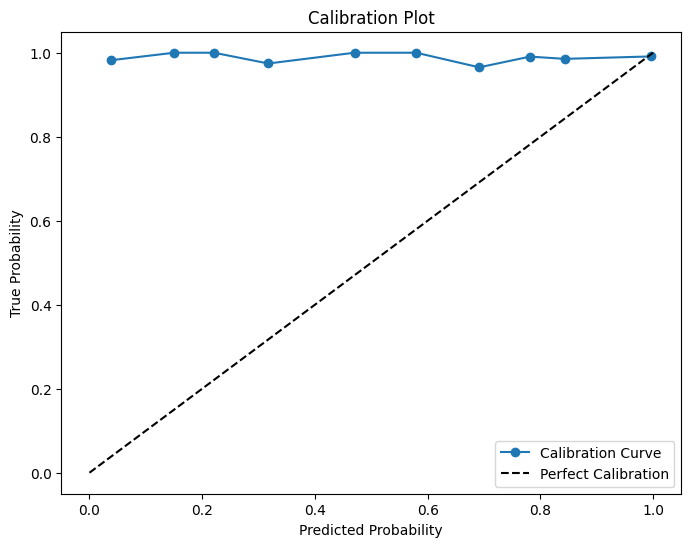

In [64]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

prob_true, prob_pred = calibration_curve(y_test, y_pred_prob, n_bins=10)

plt.figure(figsize=(8, 6))
plt.plot(prob_pred, prob_true, marker='o', label="Calibration Curve")
plt.plot([0, 1], [0, 1], 'k--', label="Perfect Calibration")
plt.xlabel("Predicted Probability")
plt.ylabel("True Probability")
plt.title("Calibration Plot")
plt.legend()
plt.show()

## Plot a pass

In [65]:
from stats.xReceiver.x_pass_get_features import get_dir_vector, get_speed
import json
import pickle


base_dir = "/Users/svasquez/driblab/outputs/FRA I 2024/624102"
row_num = 18322


match_info_path = f"{base_dir}/cached_data/match_info.json"

wy_id2team_id_path = f"{base_dir}/cached_data/wy_id2team_id.pkl"

plyr_lookup_path = f"{base_dir}/plyr_lookup_dict.json"
wy_id2plyr_id_path = f"{base_dir}/cached_data/wy_id2plyr_id.pkl"

game_path = base_dir + "/merged_tracking_events.jsonl"

with open(match_info_path, 'r') as f:
    match_info = json.load(f)

with open(wy_id2team_id_path, 'rb') as f:
    wy_id2team_id = pickle.load(f)

with open(plyr_lookup_path, 'r') as f:
    plyr_lookup_dict = json.load(f)

with open(wy_id2plyr_id_path, 'rb') as f:
    wy_id2plyr_id = pickle.load(f)

with open(game_path) as f:
    merged_tracking_jsonl = list(map(json.loads, f.read().splitlines()))


row = merged_tracking_jsonl[row_num]



In [66]:
row

{'ball': [None, None],
 'frame': 92276,
 'Videotimestamp': 3691.04,
 'period': 2,
 'data': {'7186': [{'id': 302, 'x': 61.55, 'y': 7.12, 'vis': False},
   {'id': 1161357, 'x': 25.28, 'y': 53.8, 'vis': True},
   {'id': 649929, 'x': 40.45, 'y': 44.08, 'vis': True},
   {'id': 1329669, 'x': 30.26, 'y': 18.66, 'vis': True},
   {'id': 1264738, 'x': 42.25, 'y': 21.69, 'vis': True},
   {'id': 1313893, 'x': 37.21, 'y': 34.51, 'vis': True},
   {'id': 1704693, 'x': 23.92, 'y': 33.31, 'vis': True},
   {'id': 1348196, 'x': 24.14, 'y': 43.07, 'vis': True},
   {'id': 1158575, 'x': 31.41, 'y': 51.12, 'vis': True},
   {'id': 269512, 'x': 33.45, 'y': 45.71, 'vis': True},
   {'id': 1300225, 'x': 18.24, 'y': 22.59, 'vis': False}],
  '7199': [{'id': 138449, 'x': 5.73, 'y': 31.89, 'vis': False},
   {'id': 1292674, 'x': 27.73, 'y': 43.74, 'vis': True},
   {'id': 1307264, 'x': 21.86, 'y': 47.88, 'vis': True},
   {'id': 1238610, 'x': 20.62, 'y': 32.73, 'vis': True},
   {'id': 1549623, 'x': 19.16, 'y': 23.5, 'vi

In [67]:
from stats.xR_get_features2 import get_features as get_features_new

def get_prob(plyr_id, row, wy_id2team_id, wy_id2plyr_id, merged_tracking_jsonl, plyr_lookup_dict, match_info, xgb_model): 

    # match_id = match_info.get('match_id')
    features = get_features_new(plyr_id, row, wy_id2team_id, wy_id2plyr_id, merged_tracking_jsonl, plyr_lookup_dict, match_info)

    X = features.copy()


    X_df = pd.DataFrame([X])
    
    drop_cols = ['match_id', 'event_id', 'row_num', 'giver_id', 'receiver_id', 'target']
    X_df = X_df.drop(drop_cols, axis=1)

    # Handle missing values (same as during training)
    X_df = X_df.fillna(X_train_smote.mean())

    # Ensure the column order matches the training set

    print(X_df.columns)

    print(X_train_smote.columns)
    X_df = X_df[X_train_smote.columns]

    
    

    # Predict the probability of pass success (xP)
    xP_pred = xgb_model.predict_proba(X_df)[:, 1]

    # Predict the class (success/failure)
    class_pred = xgb_model.predict(X_df)

    # Print predictions
    print(f"Predicted xP (Probability of Success): {xP_pred[0]}")
    print(f"Predicted Class (0=Unsuccessful, 1=Successful): {class_pred[0]}")

    return xP_pred[0]

plyr_id = 1329669

prob = get_prob(plyr_id=plyr_id, row=row, wy_id2team_id=wy_id2team_id, wy_id2plyr_id=wy_id2plyr_id, merged_tracking_jsonl=merged_tracking_jsonl, plyr_lookup_dict=plyr_lookup_dict, match_info=match_info, xgb_model=best_xgb_clf)
print(prob)


Index(['distance', 'theta1', 'theta2', 'dir_angle', 'giver_coord.x',
       'giver_coord.y', 'receiver_coord.x', 'receiver_coord.y', 'giver_speed',
       'receiver_speed', 'tm_count_5', 'tm_count_10', 'opp_count_2',
       'opp_count_5', 'opp_count_10', 'dist_giv_sideline', 'dist_rec_sideline',
       'num_opp2plyr_goal_giv', 'num_opp2plyr_goal_rec', 'dist_giv_goal',
       'dist_rec_goal', 'dist_opponent_giv', 'dist_opponent_rec',
       'opp_in_corridor_count', 'dist2offside', 'offside'],
      dtype='object')
Index(['distance', 'theta1', 'theta2', 'dir_angle', 'giver_coord.x',
       'giver_coord.y', 'receiver_coord.x', 'receiver_coord.y', 'giver_speed',
       'receiver_speed', 'tm_count_5', 'tm_count_10', 'opp_count_2',
       'opp_count_5', 'opp_count_10', 'dist_giv_sideline', 'dist_rec_sideline',
       'num_opp2plyr_goal_giv', 'num_opp2plyr_goal_rec', 'dist_giv_goal',
       'dist_rec_goal', 'dist_opponent_giv', 'dist_opponent_rec',
       'opp_in_corridor_count', 'dist2offsid

/Users/svasquez/driblab/dl-vision/stats/xR_get_features2.py:40: RuntimeWarning: invalid value encountered in divide
  D1_norm = D1 / np.linalg.norm(D1)
/Users/svasquez/driblab/dl-vision/stats/xR_get_features2.py:42: RuntimeWarning: invalid value encountered in divide
  D2_norm = D2 / np.linalg.norm(D2)
/Users/svasquez/driblab/dl-vision/stats/xR_get_features2.py:74: RuntimeWarning: invalid value encountered in scalar divide
  cos_theta = dot_product / magnitude_pass
/var/folders/50/x46v3vxd4b113nhtgtbw0f2c0000gp/T/ipykernel_11068/542865463.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_df = X_df.fillna(X_train_smote.mean())


In [76]:

import traceback

def get_plyrs_probs(row, wy_id2team_id, wy_id2plyr_id, merged_tracking_jsonl, plyr_lookup_dict, match_info, xgb_model):
    players_data = row.get('data')
    wy_tm_passer = row.get('team',{}).get('id')

    tm_passer = str(wy_id2team_id.get(wy_tm_passer))

    

    wy_giver_id = row.get('player', {}).get('id')
    giver_id = int(wy_id2plyr_id.get(wy_giver_id))


    

    players_probs = {}
    for team_id, players in players_data.items():
        if team_id == tm_passer:
            for player in players:
                player_id = player.get('id')

                if player_id == giver_id:
                    continue

                try:
                    prob = get_prob(player['id'] , row, wy_id2team_id, wy_id2plyr_id, merged_tracking_jsonl, plyr_lookup_dict, match_info, xgb_model)

                    # plyr_id, row, wy_id2team_id, wy_id2plyr_id, merged_tracking_jsonl, plyr_lookup_dict, match_info, xgb_model
                    players_probs[player_id] = prob

                except Exception as e:
                    traceback.print_exc()
                    
                    print(f"Error processing player {player_id}")
                    print(e)

    print(f"players_probs {players_probs}")
    return None, players_probs
    

In [81]:

# Function to plot the field and players
def plot_field_and_players(base_dir, row_num):

    

    match_info_path = f"{base_dir}/cached_data/match_info.json"

    wy_id2team_id_path = f"{base_dir}/cached_data/wy_id2team_id.pkl"

    plyr_lookup_path = f"{base_dir}/plyr_lookup_dict.json"
    wy_id2plyr_id_path = f"{base_dir}/cached_data/wy_id2plyr_id.pkl"

    game_path = base_dir + "/merged_tracking_events.jsonl"

    with open(match_info_path, 'r') as f:
        match_info = json.load(f)

    with open(wy_id2team_id_path, 'rb') as f:
        wy_id2team_id = pickle.load(f)

    with open(plyr_lookup_path, 'r') as f:
        plyr_lookup_dict = json.load(f)

    with open(wy_id2plyr_id_path, 'rb') as f:
        wy_id2plyr_id = pickle.load(f)

    with open(game_path) as f:
        merged_tracking_jsonl = list(map(json.loads, f.read().splitlines()))
    
    
    row = merged_tracking_jsonl[row_num]

    
    match_name = f" {match_info.get('home_team_name')} vs {match_info.get('away_team_name')}"

    fig, ax = plt.subplots(figsize=(10.5, 6.8))

    # Field lines
    ax.set_xlim(0, 105)
    ax.set_ylim(0, 68)

    players_data = row.get('data')
    wy_tm_passer = row.get('team',{}).get('id')
    tm_passer = str(wy_id2team_id.get(wy_tm_passer))

    hm_tm_id = str(match_info.get('home_team_id'))


    # GEt the team of the passer

    softmax_probs, players_probs = get_plyrs_probs(row, wy_id2team_id, wy_id2plyr_id, merged_tracking_jsonl, plyr_lookup_dict, match_info, best_xgb_clf)



    wy_passer_id = row.get('player', {}).get('id')
    passer_id = int(wy_id2plyr_id.get(wy_passer_id))
    
    # Get the receive id
    wy_receiver_id = row.get('pass').get('recipient').get('id')
    receiver_id = int(wy_id2plyr_id.get(wy_receiver_id))

    
    # Plot players
    for team_id, players in players_data.items():

        tm_color = 'r' if team_id == hm_tm_id else 'b'
        for player in players:

            # Determine marker size based on the player's probability (scale for better visibility)
            # prob = softmax_probs.get(player['id'], 0)
            prob = players_probs.get(player['id'], 0)
            
            marker_size = 5 + (prob/2) * 20  # Base size + scaled size according to probability



            plyr_coord = (player['x'], player['y'])
            player_dir = get_dir_vector(row, merged_tracking_jsonl, plyr_coord, player['id'])

            
            
            # Get speed of the player
            speed = get_speed(row, merged_tracking_jsonl, (player['x'], player['y']), player['id'])

            ax.arrow(plyr_coord[0], plyr_coord[1], -player_dir[0], -player_dir[1], 
                head_width=1.25, head_length=1.5 * speed , fc='green', ec='green', length_includes_head=True)
            

            # Plot the player with a shape depending on the player type
            if player['id'] == passer_id:
                ax.plot(player['x'], plyr_coord[1], color = tm_color, markersize=marker_size + 3, marker = "*")

            elif player['id'] == receiver_id:
                ax.plot(player['x'], plyr_coord[1], color = tm_color, markersize=marker_size + 3, marker = "x")
                
            else:
                ax.plot(player['x'], plyr_coord[1], color =tm_color, markersize=marker_size, marker = "o")                
            
            # Plot the shirt number
            shirt_num = plyr_lookup_dict.get(str(player['id']),{}).get('number')
            ax.text(player['x'], plyr_coord[1] + 1, str(shirt_num), fontsize=8, ha='center')
            


            # Plot the probability of the player receiving the ball
            if team_id== tm_passer:
                # prob = softmax_probs.get(player['id'])
                prob = players_probs.get(player['id'])

                if prob:
                    ax.text(player['x'], player['y'] - 1.5, f"{prob:.2f}", fontsize=8, ha='center')
    

    # Add a manual legend
    red_patch = plt.Line2D([0], [0], marker='o', color='w', label=f'{match_info.get("home_team_alias")}',
                           markerfacecolor='r', markersize=10)
    blue_patch = plt.Line2D([0], [0], marker='o', color='w', label=f'{match_info.get("away_team_alias")}',
                            markerfacecolor='b', markersize=10)
    ax.legend(handles=[red_patch, blue_patch], loc='center left', bbox_to_anchor=(1, 1), fontsize=10)


    # Field details
    ax.set_title(f'{match_name} - xP - Row Num {row.get("row_num")}')
    ax.set_xlabel('Field Length (m)')
    ax.set_ylabel('Field Width (m)')
    

    plt.show()
    
    



Index(['distance', 'theta1', 'theta2', 'dir_angle', 'giver_coord.x',
       'giver_coord.y', 'receiver_coord.x', 'receiver_coord.y', 'giver_speed',
       'receiver_speed', 'tm_count_5', 'tm_count_10', 'opp_count_2',
       'opp_count_5', 'opp_count_10', 'dist_giv_sideline', 'dist_rec_sideline',
       'num_opp2plyr_goal_giv', 'num_opp2plyr_goal_rec', 'dist_giv_goal',
       'dist_rec_goal', 'dist_opponent_giv', 'dist_opponent_rec',
       'opp_in_corridor_count', 'dist2offside', 'offside'],
      dtype='object')
Index(['distance', 'theta1', 'theta2', 'dir_angle', 'giver_coord.x',
       'giver_coord.y', 'receiver_coord.x', 'receiver_coord.y', 'giver_speed',
       'receiver_speed', 'tm_count_5', 'tm_count_10', 'opp_count_2',
       'opp_count_5', 'opp_count_10', 'dist_giv_sideline', 'dist_rec_sideline',
       'num_opp2plyr_goal_giv', 'num_opp2plyr_goal_rec', 'dist_giv_goal',
       'dist_rec_goal', 'dist_opponent_giv', 'dist_opponent_rec',
       'opp_in_corridor_count', 'dist2offsid

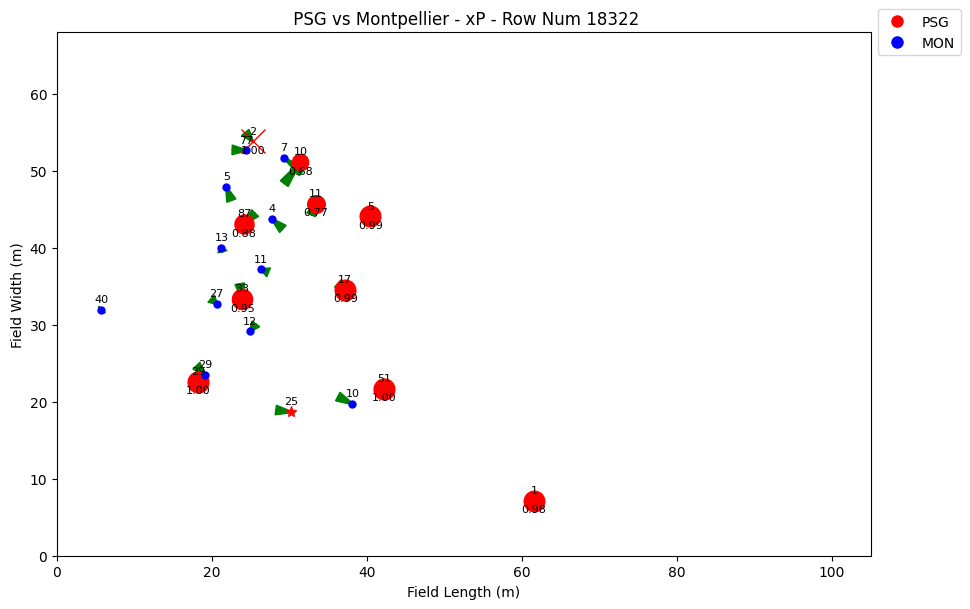

In [82]:
# Plot the field with players and ball
import traceback
base_dir = "/Users/svasquez/driblab/outputs/FRA I 2024/624102"
row_num = 18322

try:
    plot_field_and_players(base_dir, row_num)
except Exception as e:
    traceback.print_exc()